Going to do K-means using in built functions

In [2]:
#importing required library
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


In [3]:
#load the wine dataset
data = load_wine()
X = data.data
y = data.target

In [4]:
#k-mean relise on Eulien distance so standardize dataset required
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWar

Text(0, 0.5, 'Inertia')

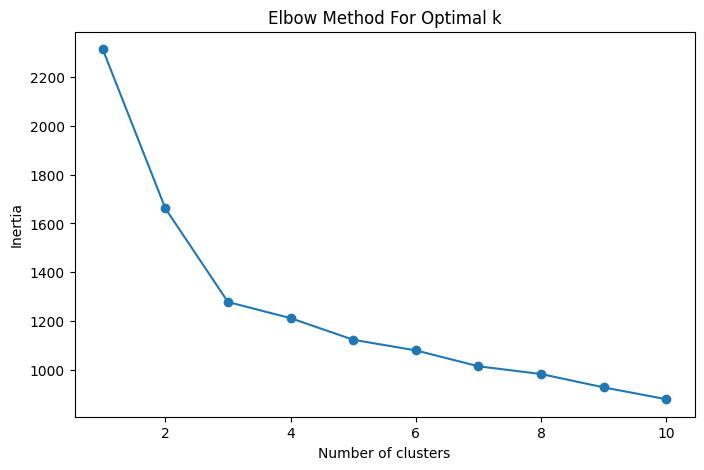

In [9]:
#Elbow method to find the optimal number of clusters
inertia = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_.__round__(2))

#Plotting the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')


In [12]:
print("Inertia values for k=1 to 10:", inertia)
for i in range(1, len(inertia)):
    print(f"Difference in inertia between k={i} and k={i+1}: {inertia[i-1] - inertia[i]}")

Inertia values for k=1 to 10: [2314.0, 1661.68, 1277.93, 1211.75, 1123.16, 1079.54, 1014.43, 982.65, 927.96, 879.43]
Difference in inertia between k=1 and k=2: 652.3199999999999
Difference in inertia between k=2 and k=3: 383.75
Difference in inertia between k=3 and k=4: 66.18000000000006
Difference in inertia between k=4 and k=5: 88.58999999999992
Difference in inertia between k=5 and k=6: 43.62000000000012
Difference in inertia between k=6 and k=7: 65.11000000000001
Difference in inertia between k=7 and k=8: 31.779999999999973
Difference in inertia between k=8 and k=9: 54.68999999999994
Difference in inertia between k=9 and k=10: 48.530000000000086


K1 to k2 difference is 652
k2 to k3 differnce is 383
k4 to k5 differnce is 66
after K3 differnce is not huge so we can choose K = 2 or 3

Text(0, 0.5, 'Difference in Inertia')

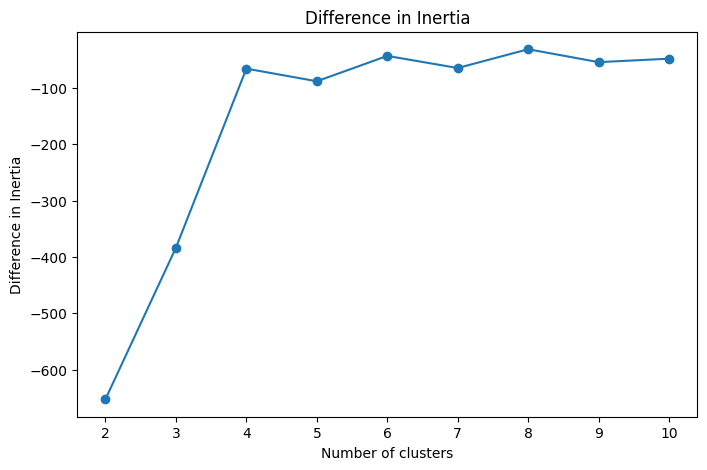

In [6]:
#difference in inertia to find the optimal k
inertia_diff = np.diff(inertia)
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia_diff, marker='o')
plt.title('Difference in Inertia')
plt.xlabel('Number of clusters')
plt.ylabel('Difference in Inertia') 

In [13]:
#fit k-means with the optimal number of clusters (k=3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
 
cluster_labels = kmeans.fit_predict(X_scaled)

/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [16]:
#checking score 
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(y, cluster_labels)
print(f"Adjusted Rand Index: {ari:.4f}")
print("Percentage of correctly clustered samples:", (ari * 100).__round__(2), "%")

Adjusted Rand Index: 0.8975
Percentage of correctly clustered samples: 89.75 %


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X


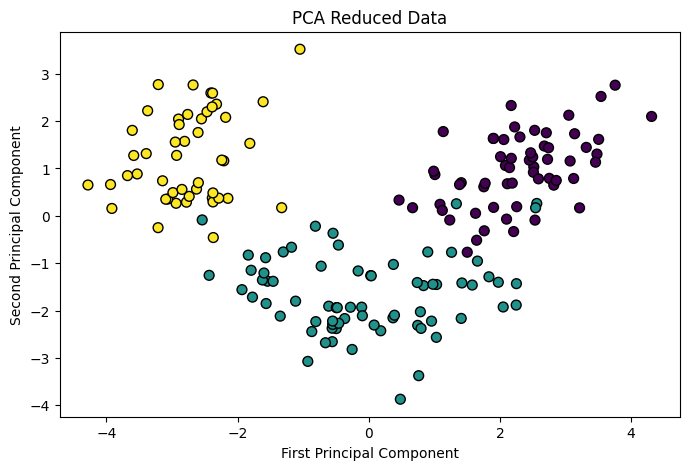

In [17]:
# Lets check accuracy after applying PCA to reduce the dimensions to 2 and then applying K-means clustering on the reduced data.

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(X_scaled)

#plot ting the PCA reduced data
plt.figure(figsize=(8, 5))
plt.scatter(x_pca[:, 0], x_pca[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
plt.title('PCA Reduced Data')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.show()

#fit k-means with the optimal number of clusters (k=3) on PCA reduced data
kmeans_pca = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
cluster_labels_pca = kmeans_pca.fit_predict(x_pca)  

In [18]:
#checking accuracy after PCA
ari_pca = adjusted_rand_score(y, cluster_labels_pca)
print(f"Adjusted Rand Index after PCA: {ari_pca:.4f}")

Adjusted Rand Index after PCA: 0.8951


Not big change in accuracy
Let do by LDA


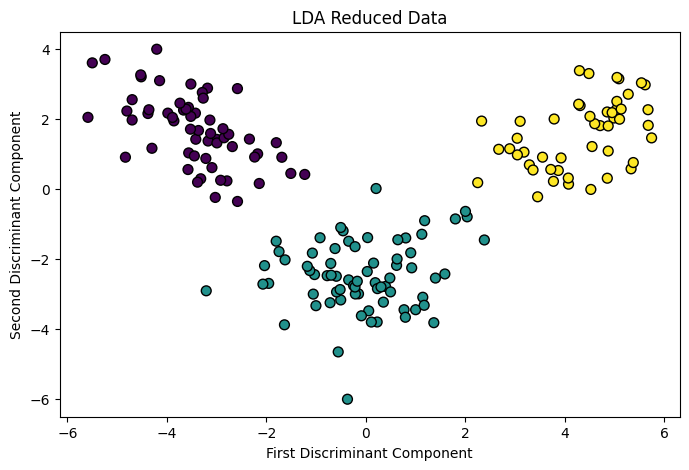

Adjusted Rand Index after LDA: 1.0000


In [19]:
#Now try with LDA and check the accuracy of K-means clustering on the LDA reduced data.
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
x_lda = lda.fit_transform(X_scaled, y)

#plotting the LDA reduced data
plt.figure(figsize=(8, 5))
plt.scatter(x_lda[:, 0], x_lda[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
plt.title('LDA Reduced Data')
plt.xlabel('First Discriminant Component')
plt.ylabel('Second Discriminant Component')
plt.show()

#fit k-means with the optimal number of clusters (k=3) on LDA reduced data
kmeans_lda = KMeans(n_clusters=optimal_k, init="k-means++", n_init=10, random_state=42)
cluster_labels_lda = kmeans_lda.fit_predict(x_lda)

#checking accuracy after LDA
ari_lda = adjusted_rand_score(y, cluster_labels_lda)
print(f"Adjusted Rand Index after LDA: {ari_lda:.4f}")

In [20]:
#now check the accuracy of K-means clustering on the LDA reduced data using the custom implementation of LDA from scratch.

ari_pca = adjusted_rand_score(y, cluster_labels_pca)
print(f"Adjusted Rand Index after PCA: {ari_pca:.4f}")

ari_lda = adjusted_rand_score(y, cluster_labels_lda)
print(f"Adjusted Rand Index after LDA: {ari_lda:.4f}")

Adjusted Rand Index after PCA: 0.8951
Adjusted Rand Index after LDA: 1.0000


when comparing both PCA and LDA , LDA give more accuracy but it leds to overfitting too.
